# 02 · Evaluation: a backtest you can trust

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/epjover/chronos2-in-practice/blob/main/notebooks/02_evaluation.ipynb)

Companion notebook for *Chronos-2 in Practice (2/7)*.

**What you will learn**

- What a rolling-origin backtest has to guarantee, and how `c2p.eval` enforces each rule
  by construction instead of by convention.
- How Chronos-2 compares with Seasonal Naive, AutoETS, MSTL and its own predecessor
  Chronos-Bolt over a year of day-ahead forecasts, with the metrics the Chronos-2 paper uses,
  and how far all of them are from the forecast the grid operator published at the time.
- How to read a skill score and its bootstrap interval, why consecutive days are resampled in
  blocks, and why a win rate is a different question from an error.
- Whether the prediction intervals are calibrated at every quantile level, and where in the
  24 hours the error sits.
- Whether a public dataset might already be in the pretraining corpus, and what
  `chronos-2-synth` can and cannot tell you about it.

Runtime: ~20 min on a GPU, ~30 min on a laptop CPU (FAST_MODE: ~1 min), plus a one-time
download of three checkpoints and the dataset.

In [1]:
# On Google Colab, clone the companion repo and install it (Colab's own PyTorch is kept).
# Locally, `uv sync` already installed everything and this cell does nothing.
import sys

if "google.colab" in sys.modules:
    !git clone --depth 1 https://github.com/epjover/chronos2-in-practice.git
    %cd chronos2-in-practice
    %pip install -q .
    import importlib

    importlib.invalidate_caches()

In [2]:
import time

import pandas as pd
from huggingface_hub.utils import logging as hub_logging
from IPython.display import Image, display
from transformers.utils import logging as transformers_logging

from c2p.baselines import MSTL, AutoETS, ChronosBolt, PublishedForecast, SeasonalNaive
from c2p.config import get_device, get_paths, is_fast_mode, set_seed
from c2p.data import spain_energy_frame, validate_and_prepare
from c2p.eval import (
    MODEL_COL,
    backtest,
    error_by_step,
    evaluate,
    reliability_table,
    rolling_origin_windows,
    skill_table,
    summarize,
)
from c2p.experiments import (
    DAILY_SEASON,
    DAY_AHEAD_BLOCK,
    FREQ,
    LOAD,
    TSO_LOAD_FORECAST,
    WEEKLY_SEASON,
    day_ahead_config,
)
from c2p.models import CHRONOS2, CHRONOS2_SYNTH, Chronos2Forecaster, load_chronos2
from c2p.plots.evaluation import (
    coverage_long,
    plot_backtest_windows,
    plot_coverage,
    plot_error_by_step,
    plot_reliability,
    plot_skill_scores,
    window_schedule,
)
from c2p.plotting import save_figure, set_style
from c2p.results import load_results, run_metadata, save_results
from c2p.schema import ID_COL, INTERVALS, TIMESTAMP_COL

FAST_MODE = is_fast_mode(default=False)  # True: 12 monthly windows instead of 365 daily ones
PATHS = get_paths(fast_mode=FAST_MODE)
set_seed()
DEVICE = get_device()
set_style()
hub_logging.set_verbosity_error()
transformers_logging.disable_progress_bar()

for key, value in run_metadata(device=DEVICE, fast_mode=FAST_MODE).items():
    print(f"{key:>20}: {value}")

              python: 3.11.17
              device: cuda
           fast_mode: False
                seed: 42
          run_at_utc: 2026-11-26 16:13
                 cpu: 12th Gen Intel(R) Core(TM) i9-12900K
     cores_available: 8
       torch_threads: 8
                 gpu: NVIDIA GeForce RTX 3070 (8 GiB)
 chronos-forecasting: 2.3.2
               torch: 2.14.1
              pandas: 3.1.0
               numpy: 2.4.6
                 fev: 0.10.0
       statsforecast: 2.0.1


## 1. What a backtest has to guarantee

Replaying history is easy to do wrong. Three rules decide whether the number at the end means
anything, and `c2p.eval` enforces all three by construction rather than by careful coding in
each notebook:

1. **The forecaster only sees the past.** It receives the rows with `timestamp <= cutoff`, and
   nothing else. A guard re-checks this immediately before every `predict` call.
2. **The horizon carries only what is known in advance.** Targets and past-only
   covariates never cross the cutoff; only columns declared as `known_covariates` do. This
   notebook declares none, so the model gets the target's history and nothing more.
3. **Actuals are joined after the model has answered**, and the join requires exactly one
   forecast row per series, target and horizon step; a model that drops, duplicates or
   misaligns a series fails loudly instead of scoring well.

The protocol itself lives in `c2p.experiments` so that every article measures the same thing:
the test period is 2018, the last year of the dataset, and each window forecasts the next 24
hours from a cutoff at 22:00 UTC (23:00 in Madrid in winter), the day-ahead problem a grid
operator solves every day. One window per day gives 365 of them.

The context is capped at 2,048 steps, the length Chronos-2 was pretrained with. That is a
choice, not a law, and notebook `03_context_length` sweeps it.

In [3]:
raw = spain_energy_frame()[[ID_COL, TIMESTAMP_COL, LOAD, TSO_LOAD_FORECAST]]
prepared, report = validate_and_prepare(raw, freq=FREQ, target=LOAD)
# The models forecast from the load alone. The operator's forecast stays out of their frame:
# any extra column in the context would reach Chronos-2 as a past covariate.
series = prepared[[ID_COL, TIMESTAMP_COL, LOAD]]
CONFIG = day_ahead_config(FAST_MODE, max_context=2048)
print(CONFIG)

windows = rolling_origin_windows(series, CONFIG)
first, last = windows[0], windows[-1]
print(
    f"{len(windows)} windows, cutoffs {first.cutoff} to {last.cutoff} UTC\n"
    f"context {len(first.context):,} h per window, horizon {CONFIG.prediction_length} h, "
    f"{CONFIG.stride} h between cutoffs"
)
print(f"Scored hours in total: {len(windows) * CONFIG.prediction_length:,}")

BacktestConfig(prediction_length=24, n_windows=365, freq='h', season_length=24, step=24, quantile_levels=(0.01, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.99), target='load_actual', known_covariates=(), max_context=2048)
365 windows, cutoffs 2017-12-31 22:00:00 to 2018-12-30 22:00:00 UTC
context 2,048 h per window, horizon 24 h, 24 h between cutoffs
Scored hours in total: 8,760


## 2. The windows that ran

The figure below is drawn from the windows the harness built, not from the configuration, so it
shows the backtest that ran rather than the one intended. Only the last week of each context is
drawn: at full length a 24-hour horizon is 1% of a 2,048-hour row and disappears.

Saved 02_window_schedule.csv


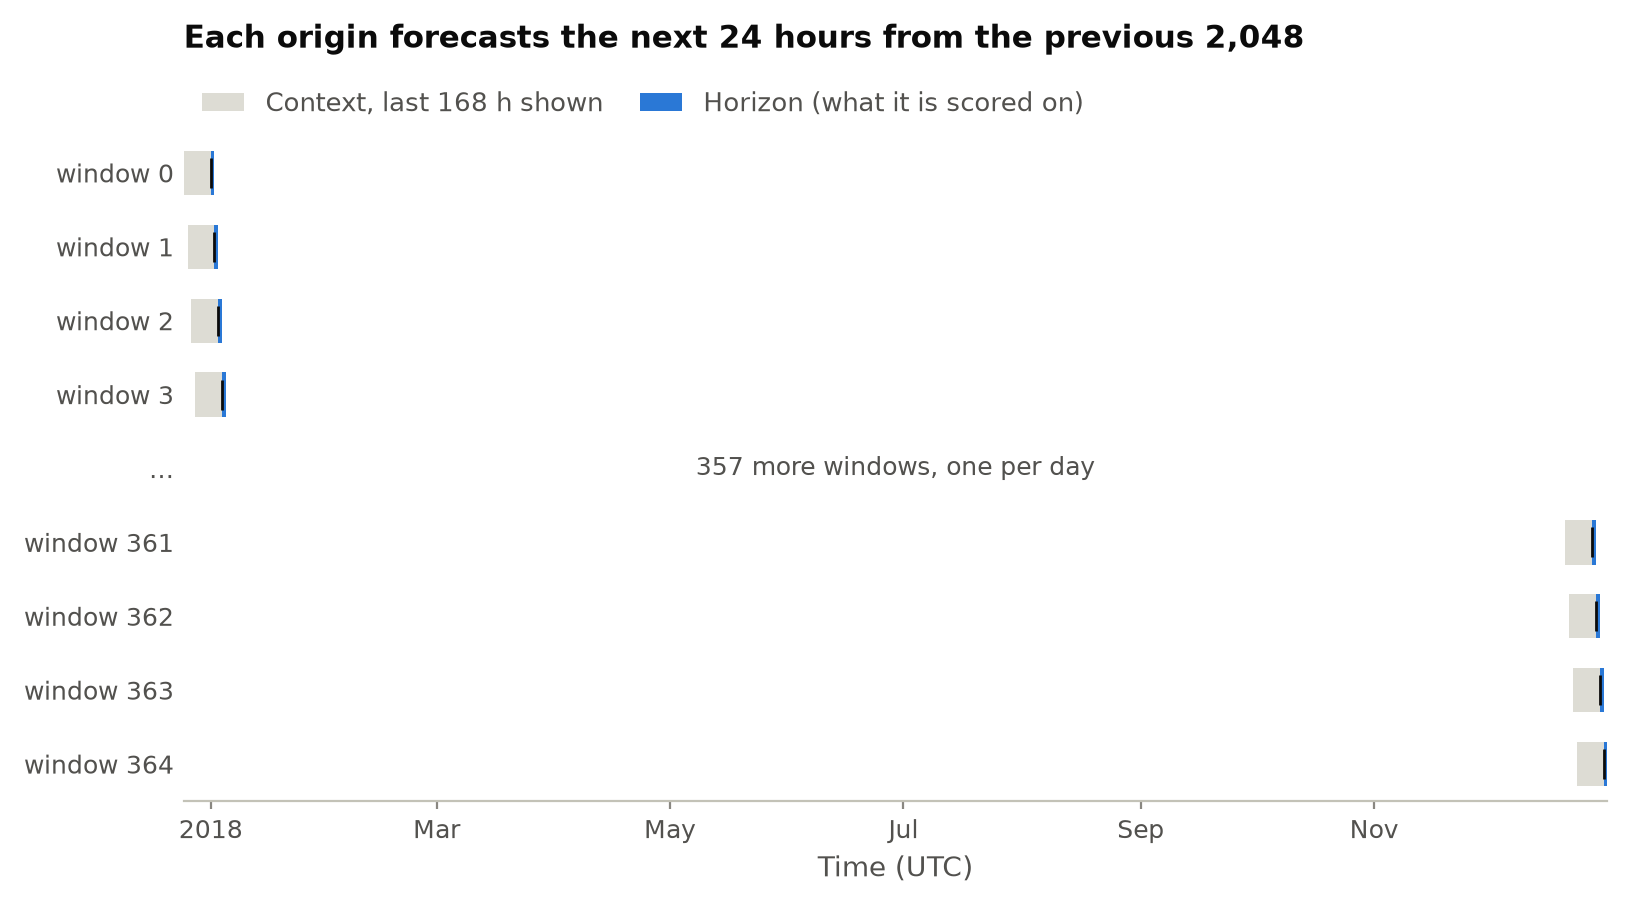

In [4]:
schedule = window_schedule(windows)
print("Saved", save_results(schedule, "02_window_schedule", PATHS).name)

dates = ["cutoff", "context_start", "horizon_end"]
schedule = load_results("02_window_schedule", PATHS, parse_dates=dates)
context_hours = int(schedule["n_context"].iloc[-1])
ax = plot_backtest_windows(
    schedule,
    context_shown=pd.Timedelta(days=7),
    title=(
        f"Each origin forecasts the next {CONFIG.prediction_length} hours "
        f"from the previous {context_hours:,}"
    ),
    xlabel="Time (UTC)",
)
(figure_path,) = save_figure(ax.figure, "02_backtest_windows", PATHS.figures)
display(Image(filename=figure_path, width=800))

## 3. The models, and why these baselines

Without baselines a metric is unreadable: is a WQL of 0.03 good? The answer only exists relative
to something.

- **Seasonal Naive** repeats the value from one season earlier (here, 24 hours). It is the
  reference of every skill score in the Chronos-2 paper and in fev-bench, and on strongly
  seasonal data it is much harder to beat than it sounds.
- **Seasonal Naive (weekly)** repeats the value from 168 hours earlier instead. Electricity
  demand has a weekly cycle as well as a daily one, so this guards against the charge that the
  skill scores below are flattering because the reference was too weak. It is reported as a
  model, while the skill scores keep using the 24-hour version for comparability with the paper.
- **AutoETS** picks an exponential-smoothing model per series by AICc. It is the classical
  statistical answer, and it is fitted to the series it forecasts, which a pretrained model
  does not. One limitation to keep in mind when reading its row: statsforecast fits seasonal ETS
  models up to a period of 24, so this AutoETS can represent the daily cycle but *not* the
  weekly one.
- **MSTL** is the classical model that does fit both cycles: it splits the series into a
  daily component, a weekly component and a trend, repeats the two seasonal components and
  forecasts the rest with a non-seasonal ETS. It is the fair classical contender on this series.
- **Chronos-Bolt** is the previous Chronos generation, one call away in the same library. It
  turns "is Chronos-2 better?" into a measurement rather than a release note.
- **The operator's forecast** is not a model we run. The dataset carries the day-ahead load
  forecast that the Spanish grid operator published at the time (`total load forecast`). EU
  Regulation 543/2013 (Article 6) requires that forecast to be public at the latest two hours
  before the day-ahead market closes, around ten in the morning of the previous day, so it
  was available well before our 22:00 UTC cutoff. `PublishedForecast` replays it through the
  same windows and metrics. It is a point forecast, so its WQL equals its WAPE and its coverage
  means nothing; and the operator had what none of the models here have: weather forecasts, the
  calendar, and years of tuning on this one series. It is the reference that says how far a
  zero-shot model is from the professional answer.

One caveat the code will warn about: Bolt was trained on the nine deciles only, so its 0.01 and
0.99 quantiles are clamped to its 0.1 and 0.9 ones. Its "98% interval" is really its 80% one,
which section 6 will show rather than argue.

In [5]:
chronos = Chronos2Forecaster(load_chronos2(CHRONOS2, device=DEVICE))
MODELS = [
    chronos,
    SeasonalNaive(season_length=DAILY_SEASON),
    SeasonalNaive(season_length=WEEKLY_SEASON, name="seasonal_naive_weekly"),
    AutoETS(season_length=DAILY_SEASON),
    MSTL(season_lengths=(DAILY_SEASON, WEEKLY_SEASON)),
    ChronosBolt(device=DEVICE),
]
OPERATOR = PublishedForecast(TSO_LOAD_FORECAST, name="operator_forecast")
# Same windows; the only difference is that the operator's column is declared as known.
OPERATOR_CONFIG = day_ahead_config(
    FAST_MODE, known_covariates=(TSO_LOAD_FORECAST,), max_context=2048
)
print("Models:", ", ".join(model.name for model in [*MODELS, OPERATOR]))

Models: chronos-2, seasonal_naive, seasonal_naive_weekly, auto_ets, mstl, chronos-bolt, operator_forecast


## 4. Running the backtest

Every model sees the same windows, in the same order, oldest first.

In [6]:
start = time.perf_counter()
forecasts = pd.concat([backtest(model, series, CONFIG) for model in MODELS], ignore_index=True)
operator_forecasts = backtest(OPERATOR, prepared, OPERATOR_CONFIG)
elapsed = time.perf_counter() - start
print(f"{len(MODELS) + 1} models x {CONFIG.n_windows} windows in {elapsed / 60:.1f} min")

metrics = pd.concat(
    [
        evaluate(forecasts, series, CONFIG),
        evaluate(operator_forecasts, prepared, OPERATOR_CONFIG),
    ],
    ignore_index=True,
)
print("Saved", save_results(metrics, "02_backtest_metrics", PATHS).name)

# Two tables that need the forecasts themselves, not the per-window metrics.
print("Saved", save_results(reliability_table(forecasts), "02_reliability", PATHS).name)
by_step = error_by_step(pd.concat([forecasts, operator_forecasts], ignore_index=True))
print("Saved", save_results(by_step, "02_error_by_step", PATHS).name)

7 models x 365 windows in 9.0 min
Saved 02_backtest_metrics.csv
Saved 02_reliability.csv
Saved 02_error_by_step.csv


chronos-bolt was trained on quantile levels in [0.1, 0.9]; the levels [0.01, 0.99] are clamped to the nearest trained level, so their intervals are too narrow.


## 5. Against the baselines

`summarize` averages each metric over the windows. WQL scores the whole predictive
distribution, MASE and WAPE the median only; `seconds` is the wall-clock time of one window's
`predict` call, which here includes AutoETS fitting a model from scratch every time.

In [7]:
metrics = load_results("02_backtest_metrics", PATHS)
summary = summarize(metrics)
# A point forecast has no interval: its "coverage" would be the share of exact hits.
intervals = [column for column in summary.columns if column.startswith("coverage_")]
summary.loc[summary[MODEL_COL] == OPERATOR.name, intervals] = float("nan")
print("Saved", save_results(summary, "02_model_summary", PATHS).name)
columns = ["model", "n_windows", "WQL", "MASE", "WAPE", "coverage_80", "coverage_98", "seconds"]
summary[columns].round(4)

Saved 02_model_summary.csv


,model,n_windows,WQL,MASE,WAPE,coverage_80,coverage_98,seconds
0,operator_forecast,365,0.0094,0.1072,0.0094,NaN,NaN,0.0083
1,chronos-bolt,365,0.0343,0.4919,0.0430,0.8235,0.8235,0.0403
2,chronos-2,365,0.0388,0.5362,0.0467,0.7342,0.9361,0.0361
3,mstl,365,0.0522,0.7200,0.0628,0.8139,0.9367,0.3653
4,seasonal_naive,365,0.0748,1.0097,0.0885,0.8150,0.9601,0.0138
5,seasonal_naive_weekly,365,0.0782,1.0563,0.0924,0.8214,0.9495,0.0138
6,auto_ets,365,0.1046,1.6062,0.1371,0.7166,0.9849,0.9152


A mean hides how often a model wins. The skill score fixes both problems at once: it is
`1 - geometric mean(model error / baseline error)` over the windows, with a 95% bootstrap
interval, as fev-bench computes it, except that the units here are the windows of one
dataset instead of the tasks of a benchmark, so these numbers are *not* comparable with the
leaderboard of article 1. The win rate is the share of windows in which the model beats the
baseline.

One more difference from fev-bench. Its units are separate tasks; ours are consecutive days,
and a bad day tends to follow a bad day (the log error ratio against the seasonal naive has a
lag-1 autocorrelation of 0.47). Resampling days one by one would treat a cold week as seven
independent draws and give an interval that is too narrow, so `block_length=DAY_AHEAD_BLOCK`
resamples runs of seven consecutive windows instead. The point estimate does not change.

In [8]:
skill = skill_table(metrics, baseline="seasonal_naive", metric="WQL", block_length=DAY_AHEAD_BLOCK)
print("Saved", save_results(skill, "02_skill_table", PATHS).name)
skill.round(4)

Saved 02_skill_table.csv


,model,baseline,metric,skill,ci_low,ci_high,win_rate,n_units,block_length
0,operator_forecast,seasonal_naive,WQL,0.8658,0.8538,0.8769,1.0000,365,7
1,chronos-2,seasonal_naive,WQL,0.6386,0.5749,0.6912,0.8384,365,7
2,chronos-bolt,seasonal_naive,WQL,0.6213,0.5663,0.6667,0.8849,365,7
3,mstl,seasonal_naive,WQL,0.3093,0.2622,0.3546,0.7644,365,7
4,seasonal_naive,seasonal_naive,WQL,0.0000,0.0000,0.0000,0.5000,365,7
5,seasonal_naive_weekly,seasonal_naive,WQL,-0.0254,-0.0929,0.0402,0.4329,365,7
6,auto_ets,seasonal_naive,WQL,-0.6546,-0.7740,-0.5326,0.2384,365,7


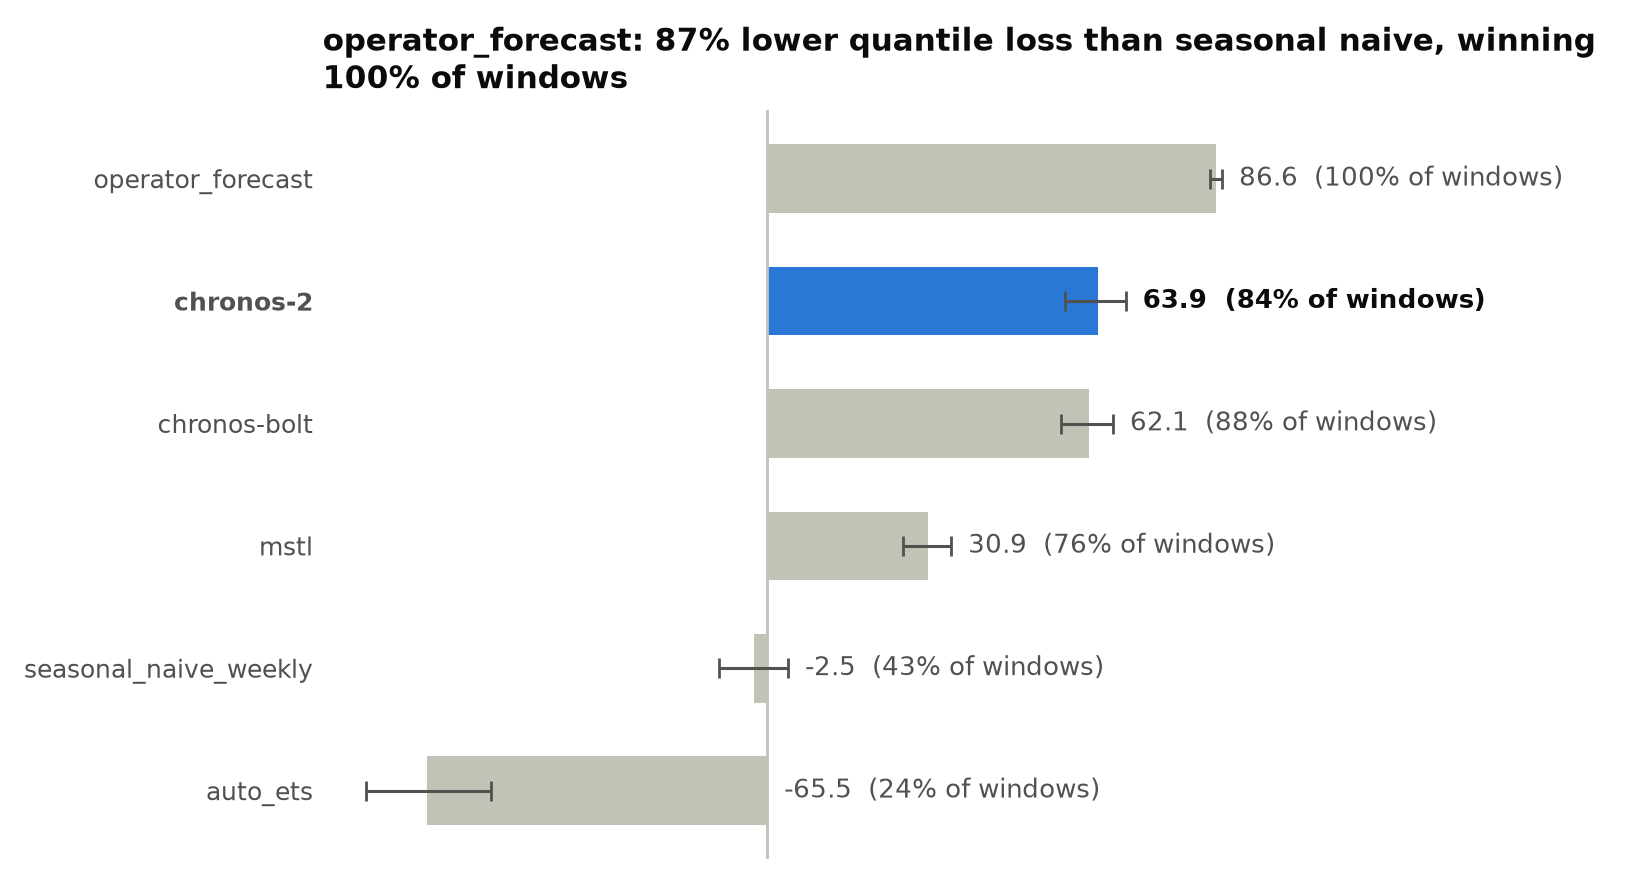

In [9]:
skill = load_results("02_skill_table", PATHS)
best = skill.iloc[0]
title = (
    f"{best['model']}: {best['skill']:.0%} lower quantile loss than seasonal naive, "
    f"winning {best['win_rate']:.0%} of windows"
)
ax = plot_skill_scores(skill, title=title)
(figure_path,) = save_figure(ax.figure, "02_skill_scores", PATHS.figures)
display(Image(filename=figure_path, width=800))

## 6. Do the intervals keep their promise?

Accuracy and calibration are different questions. An 80% interval promises that the actual
value falls inside it 80% of the time; a model can have the best median forecast and still lie
about its own uncertainty. Over 365 windows the law of large numbers applies, so this is the
place to check it.

Saved 02_coverage.csv


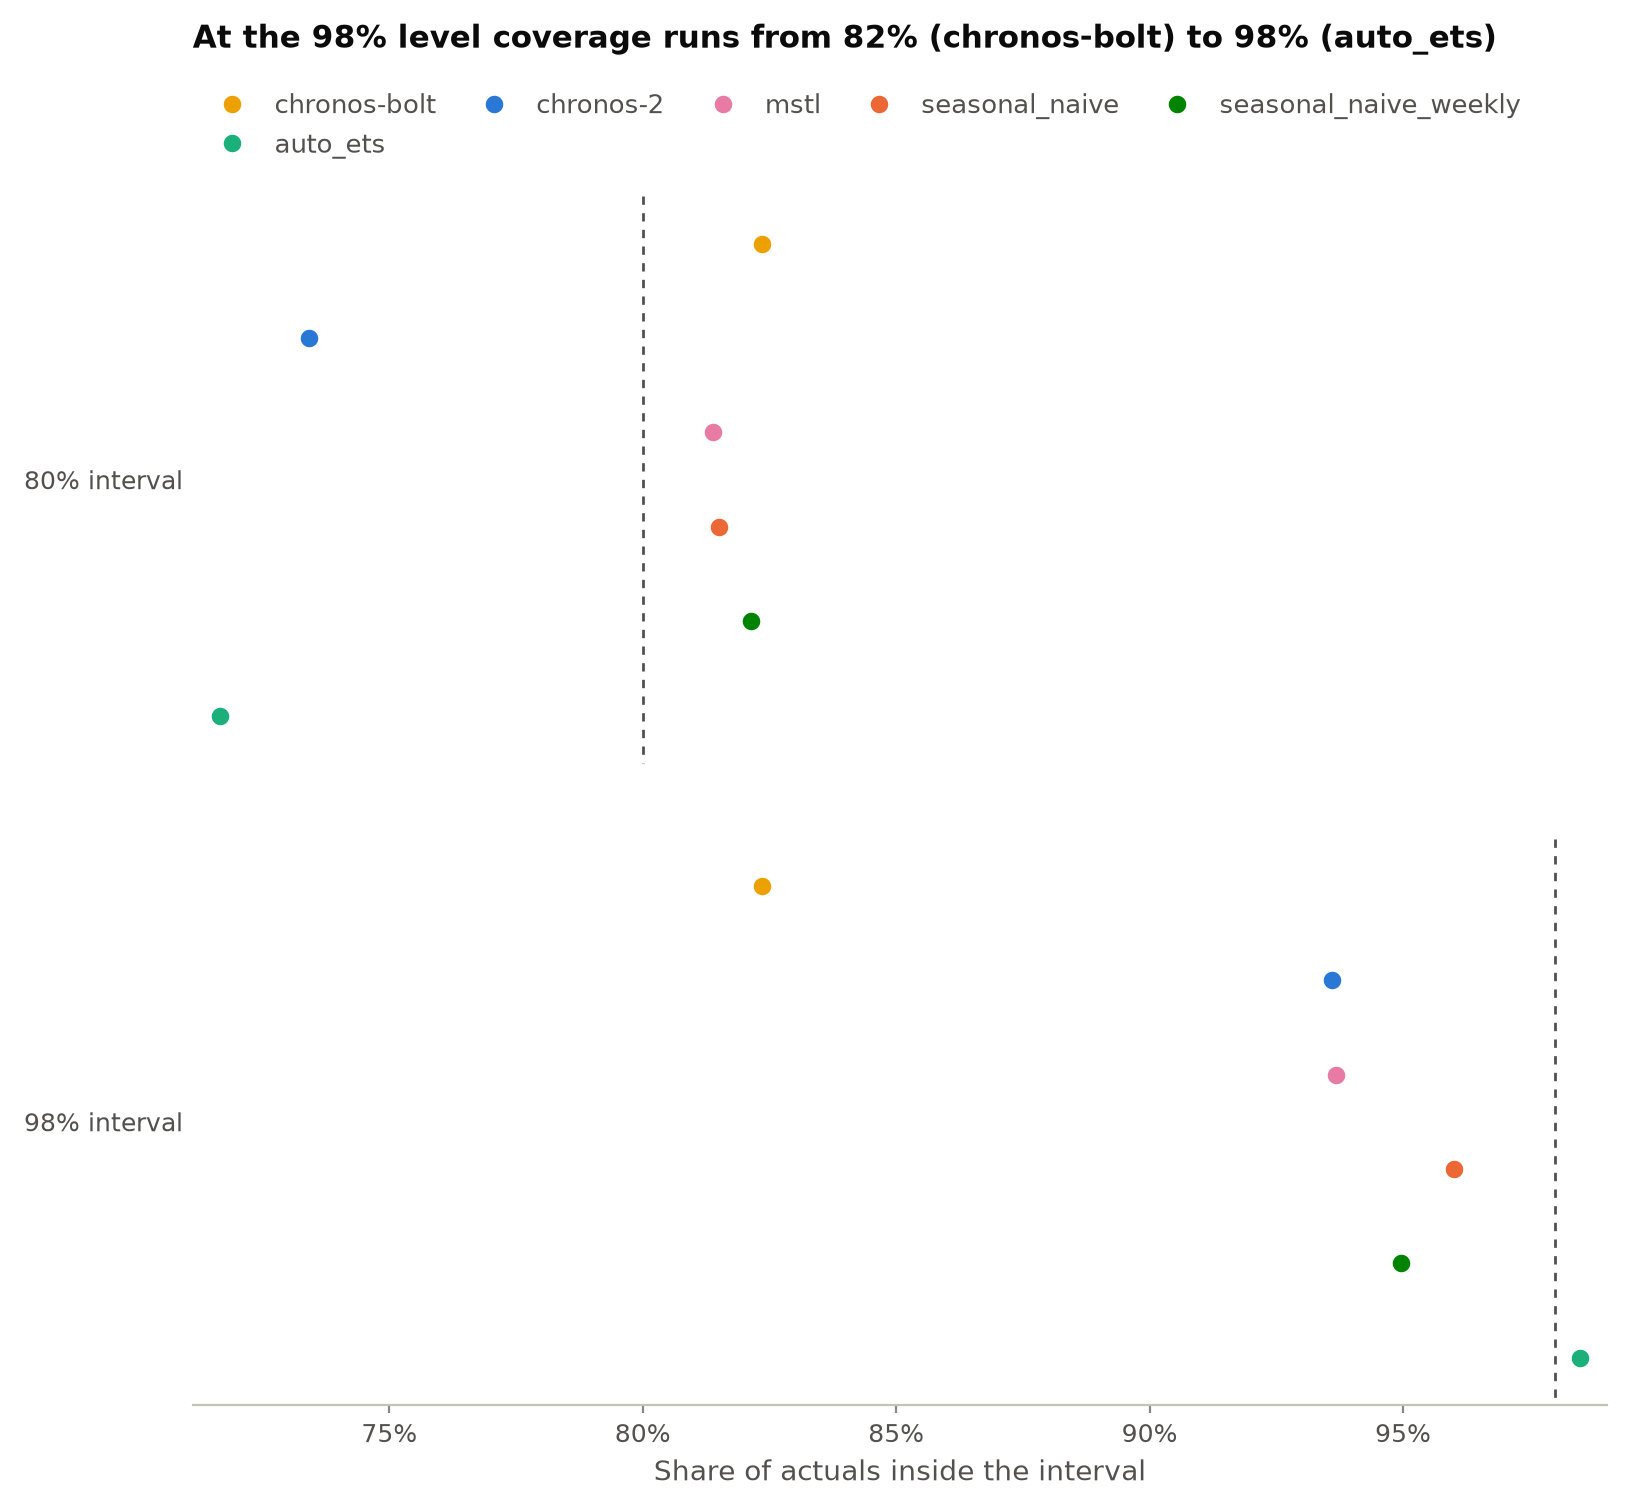

In [10]:
summary = load_results("02_model_summary", PATHS)
# A point forecast has no interval to check.
coverage = coverage_long(summary[summary[MODEL_COL] != OPERATOR.name], INTERVALS)
print("Saved", save_results(coverage, "02_coverage", PATHS).name)

coverage = load_results("02_coverage", PATHS)
widest = coverage[coverage["nominal"] == 0.98].set_index("model")["achieved"]
title = (
    f"At the 98% level coverage runs from {widest.min():.0%} ({widest.idxmin()}) "
    f"to {widest.max():.0%} ({widest.idxmax()})"
)
ax = plot_coverage(coverage, title=title)
(figure_path,) = save_figure(ax.figure, "02_coverage", PATHS.figures)
display(Image(filename=figure_path, width=800))

### Every level, not just two intervals

Two intervals are two points of the predictive distribution. The reliability table checks all
nine deciles: for each level, the share of the 8,760 actuals that fell at or below that
quantile. A calibrated model is on the zero line. Intervals that are too narrow show up as a
curve above zero on the left (too many actuals under the low quantiles) and below zero on the
right.

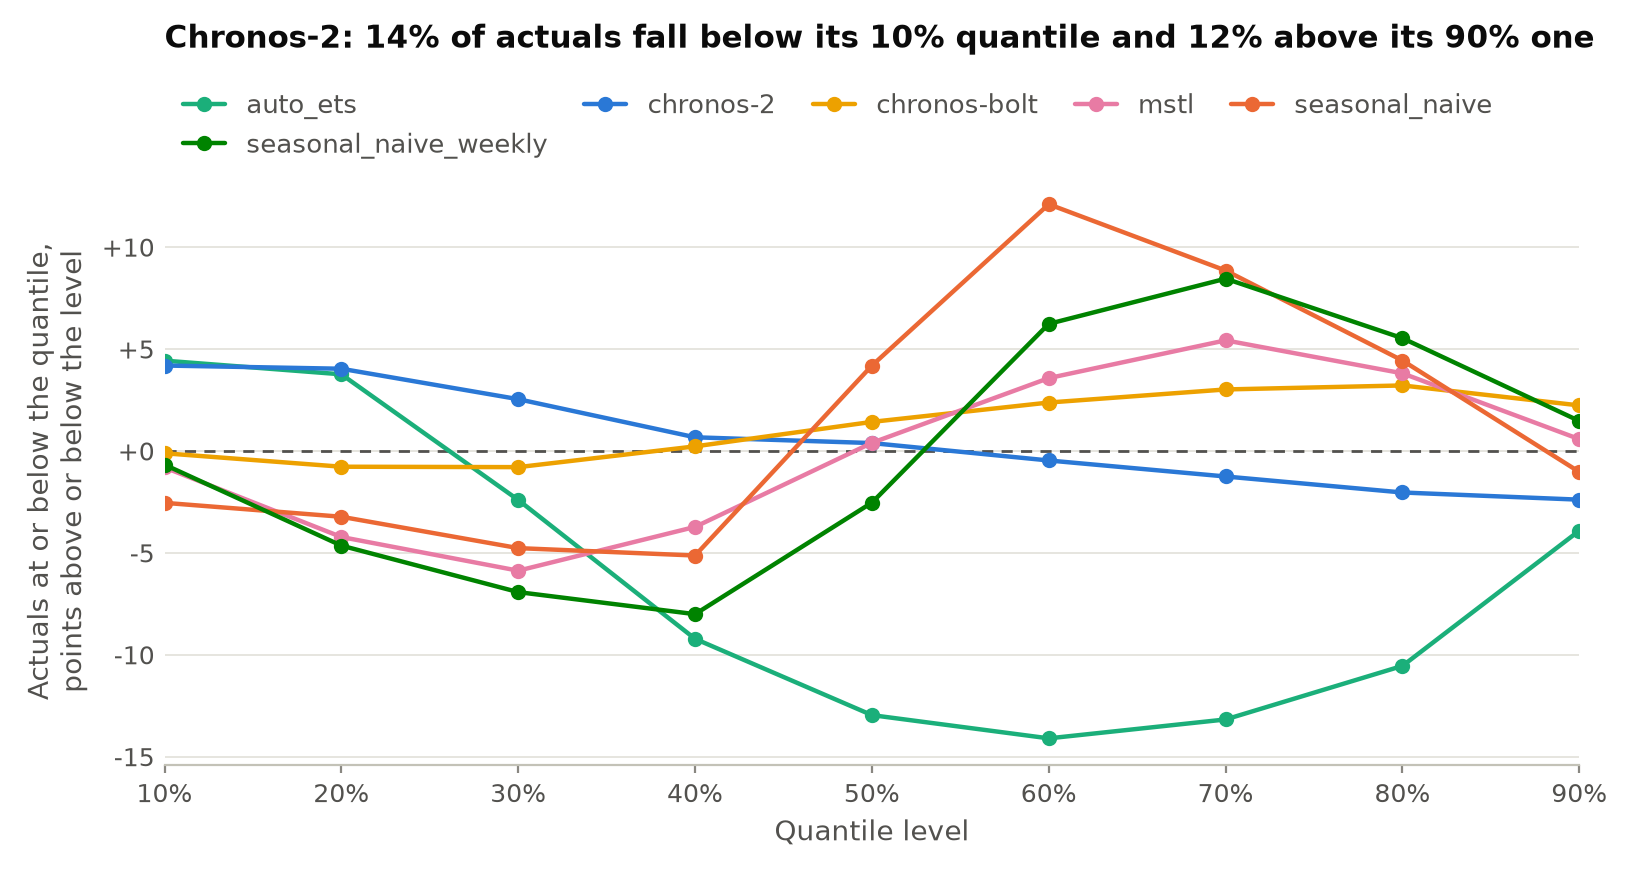

model,auto_ets,chronos-2,chronos-bolt,mstl,seasonal_naive,seasonal_naive_weekly
level,,,,,,
0.1,0.144,0.142,0.099,0.092,0.075,0.093
0.2,0.238,0.240,0.192,0.158,0.168,0.154
0.3,0.276,0.325,0.292,0.241,0.252,0.231
0.4,0.308,0.407,0.402,0.363,0.349,0.320
0.5,0.370,0.504,0.514,0.504,0.542,0.475
0.6,0.459,0.595,0.624,0.636,0.721,0.662
0.7,0.568,0.687,0.730,0.754,0.789,0.785
0.8,0.695,0.780,0.832,0.838,0.844,0.855
0.9,0.861,0.876,0.922,0.906,0.890,0.915


In [11]:
reliability = load_results("02_reliability", PATHS)
chronos_rows = reliability[reliability[MODEL_COL] == chronos.name].set_index("level")["observed"]
title = (
    f"Chronos-2: {chronos_rows.loc[0.1]:.0%} of actuals fall below its 10% quantile "
    f"and {1 - chronos_rows.loc[0.9]:.0%} above its 90% one"
)
ax = plot_reliability(reliability, title=title)
(figure_path,) = save_figure(ax.figure, "02_reliability", PATHS.figures)
display(Image(filename=figure_path, width=800))
reliability.pivot_table(index="level", columns=MODEL_COL, values="observed").round(3)

### Where in the day the error sits

The horizon is 24 hours from 23:00 UTC, so step 1 is midnight in Madrid in winter and step 9
is eight in the morning. `error_by_step` pools the 365 windows by step. The operator's forecast
is on the same axes: it is the gap that a zero-shot model leaves at each hour.

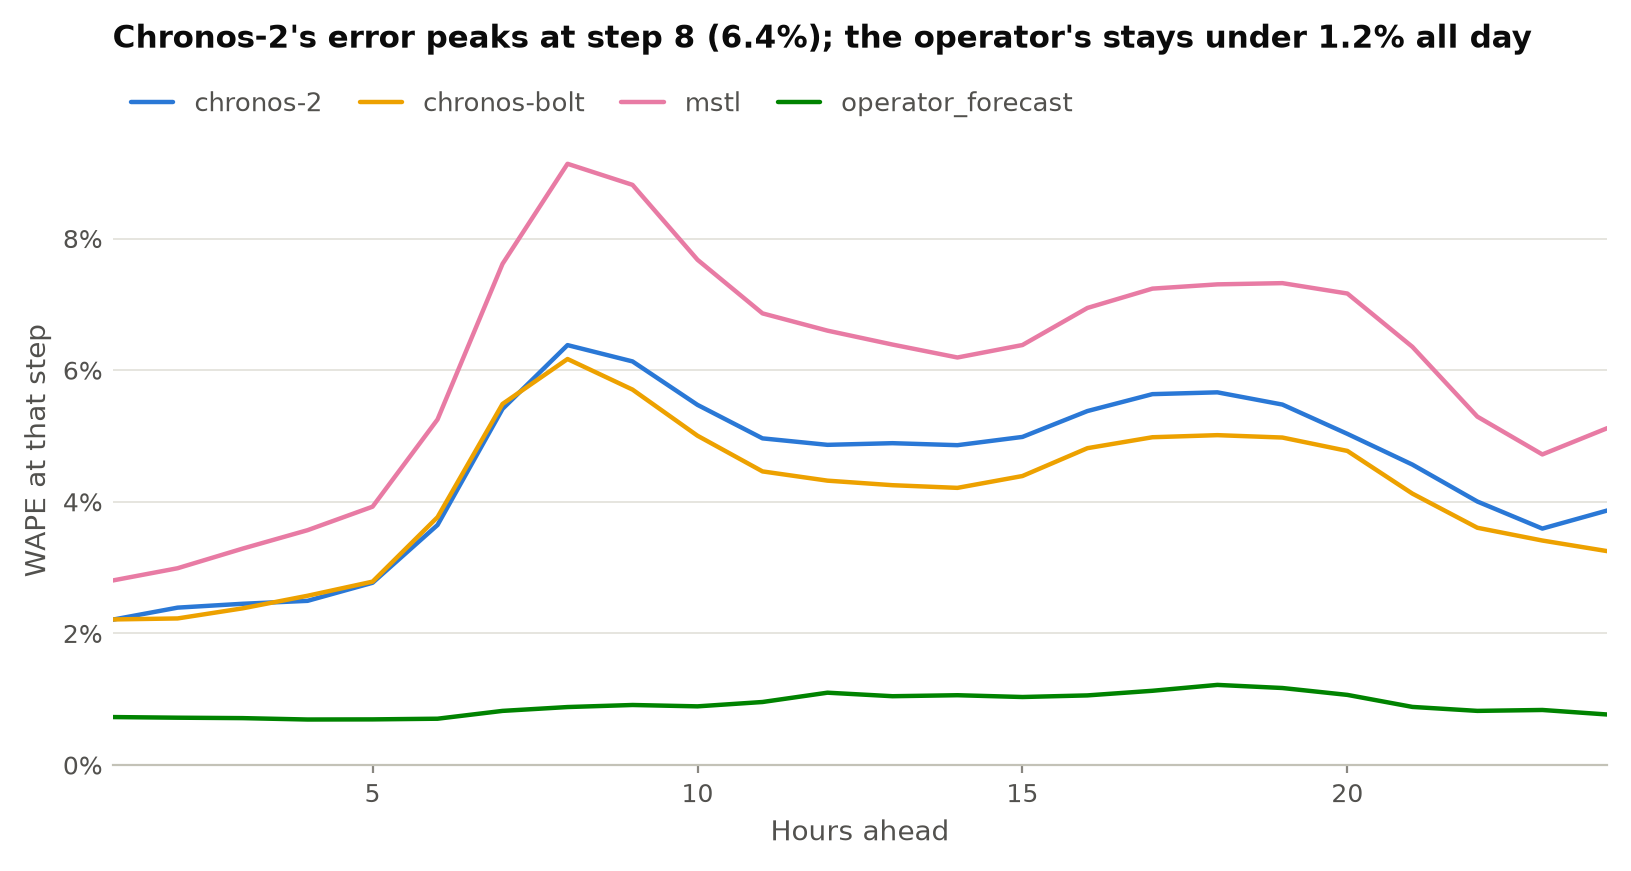

In [12]:
by_step = load_results("02_error_by_step", PATHS)
shown = by_step[by_step[MODEL_COL].isin([chronos.name, "chronos-bolt", "mstl", OPERATOR.name])]
wide = shown.pivot_table(index="step", columns=MODEL_COL, values="WAPE")
title = (
    f"Chronos-2's error peaks at step {wide[chronos.name].idxmax()} "
    f"({wide[chronos.name].max():.1%}); "
    f"the operator's stays under {wide[OPERATOR.name].max():.1%} all day"
)
ax = plot_error_by_step(shown, metric="WAPE", title=title, xlabel="Hours ahead")
(figure_path,) = save_figure(ax.figure, "02_error_by_step", PATHS.figures)
display(Image(filename=figure_path, width=800))

## 7. Could the model have seen this dataset?

The Spanish dataset is public and predates the model, so the question to ask is whether it sits
in the pretraining corpus. Appendix A of the technical report lists that corpus; this dataset is
not named in it, but "not named" is weaker than "not seen": an overlapping series could enter
through an aggregated source.

`autogluon/chronos-2-synth` is the published control: the same architecture trained *only* on
synthetic data, so it cannot have seen any real dataset. If the two score about the same here,
contamination is not driving the result. If the real-data model is much better on this dataset
than the synthetic-only one is in general, that is a flag to follow up (not a proof, because
real pretraining data also helps without any leak).

In [13]:
synth = Chronos2Forecaster(load_chronos2(CHRONOS2_SYNTH, device=DEVICE), name="chronos-2-synth")
synth_metrics = evaluate(backtest(synth, series, CONFIG), series, CONFIG)
print("Saved", save_results(synth_metrics, "02_synth_metrics", PATHS).name)

pair = pd.concat(
    [metrics[metrics[MODEL_COL] == chronos.name], load_results("02_synth_metrics", PATHS)],
    ignore_index=True,
)
contamination = skill_table(pair, baseline=chronos.name, metric="WQL", block_length=DAY_AHEAD_BLOCK)
print("Saved", save_results(contamination, "02_contamination", PATHS).name)
contamination.round(4)

Saved 02_synth_metrics.csv
Saved 02_contamination.csv


,model,baseline,metric,skill,ci_low,ci_high,win_rate,n_units,block_length
0,chronos-2,chronos-2,WQL,0.0000,0.0000,0.0000,0.5,365,7
1,chronos-2-synth,chronos-2,WQL,-0.1678,-0.2518,-0.0896,0.4,365,7


In [14]:
contamination = load_results("02_contamination", PATHS)
row = contamination.set_index("model").loc["chronos-2-synth"]
gap = -row["skill"]  # skill of synth vs chronos-2: negative means synth is worse
print(
    f"chronos-2-synth is {abs(gap):.1%} {'worse' if gap > 0 else 'better'} than chronos-2 "
    f"in WQL on a typical window, 95% interval "
    f"[{-row['ci_high']:+.1%}, {-row['ci_low']:+.1%}], beating it in "
    f"{row['win_rate']:.0%} of windows."
)

chronos-2-synth is 16.8% worse than chronos-2 in WQL on a typical window, 95% interval [+9.0%, +25.2%], beating it in 40% of windows.


## 8. Summary

Read back from `results/`, so every number below is the one in the CSV:

In [15]:
summary = load_results("02_model_summary", PATHS).set_index("model")
skill = load_results("02_skill_table", PATHS).set_index("model")
coverage = load_results("02_coverage", PATHS)

print(f"{CONFIG.n_windows} day-ahead windows over 2018, {CONFIG.prediction_length} h each\n")
print(f"{'model':<22} {'WQL':>8} {'MASE':>7} {'WAPE':>7} {'skill':>8} {'win':>6} {'cov80':>7}")
for model in summary.sort_values("WQL").index:
    row, sk = summary.loc[model], skill.loc[model]
    covered = "n/a" if pd.isna(row["coverage_80"]) else f"{row['coverage_80']:.1%}"
    print(
        f"{model:<22} {row['WQL']:8.4f} {row['MASE']:7.3f} {row['WAPE']:7.3f} "
        f"{sk['skill']:8.1%} {sk['win_rate']:6.0%} {covered:>7}"
    )

365 day-ahead windows over 2018, 24 h each

model                       WQL    MASE    WAPE    skill    win   cov80
operator_forecast        0.0094   0.107   0.009    86.6%   100%     n/a
chronos-bolt             0.0343   0.492   0.043    62.1%    88%   82.4%
chronos-2                0.0388   0.536   0.047    63.9%    84%   73.4%
mstl                     0.0522   0.720   0.063    30.9%    76%   81.4%
seasonal_naive           0.0748   1.010   0.089     0.0%    50%   81.5%
seasonal_naive_weekly    0.0782   1.056   0.092    -2.5%    43%   82.1%
auto_ets                 0.1046   1.606   0.137   -65.5%    24%   71.7%


**What this establishes for the rest of the series**

- A number to beat, measured the same way in every later article: the WQL above is the
  zero-shot reference that covariates (article 3) and fine-tuning (article 4) have to improve.
- A protocol: same windows, same metrics, same baseline, so later gains are comparable.
- A calibration baseline: whatever covariates or fine-tuning do to accuracy, section 6 is the
  check that they did not quietly break the intervals.
- A ceiling: the operator's forecast is what a specialised system with weather forecasts
  achieves on this series, and the distance to it is the room that covariates have to work in.

**Next:** [`03_context_length`](03_context_length.ipynb) asks how much history Chronos-2
uses, and [`04_multivariate_coldstart`](04_multivariate_coldstart.ipynb) asks what
happens when a series barely has any.